# 🧭 Partie 3 — Classification : Prédire le genre musical (`playlist_genre`)

Dans cette partie, notre objectif est de construire un modèle de Machine Learning capable de prédire le genre musical d'un morceau parmi **6 classes** (`edm`, `latin`, `pop`, `r&b`, `rap`, `rock`) à partir de ses caractéristiques audio, de sa durée et de sa popularité.

In [9]:
# =========================================================
# ÉTAPE 3.1 : Chargement, Préparation et Train/Test Split
# =========================================================
import sys
sys.path.insert(0, "..")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from config import RANDOM_STATE, TEST_SIZE, TARGET_CLF, FEATURES_CLF
from data import load_data, clean_data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

# 1. Chargement et nettoyage des données
df = load_data()
df_clean = clean_data(df)

# Choix des variables explicatives : les caractéristiques audio de base + track_popularity 
# (On évite soigneusement le sous-genre pour éliminer tout risque de data leakage / triche)
features_clf_propre = FEATURES_CLF + ['track_popularity']

X_clf = df_clean[features_clf_propre]
y_clf = df_clean[TARGET_CLF]

print(f"Dimensions de X_clf : {X_clf.shape}")
print(f"Dimensions de y_clf : {y_clf.shape}")

# 2. Séparation Train / Test stratifiée (essentiel pour conserver les proportions de chaque genre)
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, 
    y_clf, 
    test_size=TEST_SIZE, 
    random_state=RANDOM_STATE, 
    stratify=y_clf
)
print(f"Taille du train : {X_clf_train.shape[0]} lignes | Taille du test : {X_clf_test.shape[0]} lignes")

Dimensions de X_clf : (27786, 14)
Dimensions de y_clf : (27786,)
Taille du train : 22228 lignes | Taille du test : 5558 lignes


### 📉 Étape 3.2 : Le Modèle Naïf (Baseline) et la question du hasard

Avant d'entraîner des algorithmes complexes, définissons notre point de comparaison (*baseline*).
* **Question de l'énoncé :** Quel est le score d'un modèle qui répondrait au hasard parmi 6 genres ? 
  * *Réponse :* S'il répondait complètement au hasard de manière uniforme, l'accuracy serait de **1 / 6 soit environ 16.67%**. 
  * *Modèle naïf (classe majoritaire) :* Notre modèle naïf prédit systématiquement la classe la plus fréquente dans le jeu d'entraînement (le rap). Son accuracy sert de **score plancher à battre**.

In [10]:
# Code de la baseline
majority_class = y_clf_train.mode()[0]
y_naive_pred = [majority_class] * len(y_clf_test)
naive_accuracy = accuracy_score(y_clf_test, y_naive_pred)

print(f"Classe majoritaire prédite : {majority_class}")
print(f"Accuracy du modèle naïf (score plancher à battre) : {naive_accuracy:.4f}")

Classe majoritaire prédite : rap
Accuracy du modèle naïf (score plancher à battre) : 0.1851


### 🤖 Étape 3.3 & 3.4 : Régression Logistique et KNN (Analyse de l'Overfitting)
* **Régression Logistique :** Modèle linéaire simple. Nécessite une standardisation des variables (`StandardScaler`) pour que chaque caractéristique audio pèse de manière équitable dans le calcul, en évitant le *data leakage* en faisant le `fit` uniquement sur le train via un `Pipeline`.
* **K-Nearest Neighbors (KNN) :** Algorithme basé sur la distance entre les voisins. En testant plusieurs valeurs de $k$, on observe le phénomène d'**overfitting** (surapprentissage) : quand $k$ est très petit ($k=3$), le modèle apprend par cœur le jeu d'entraînement (score de 100% sur le train) mais généralise mal sur le test.

In [ ]:
# Régression Logistique
model_clf_log = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
model_clf_log.fit(X_clf_train, y_clf_train)
y_pred_log = model_clf_log.predict(X_clf_test)

log_accuracy = accuracy_score(y_clf_test, y_pred_log)
log_f1_macro = f1_score(y_clf_test, y_pred_log, average='macro')

# KNN : Test de plusieurs k pour repérer l'overfitting
k_values = [3, 5, 11, 21]
knn_results = []
best_k_acc = 0

for k in k_values:
    knn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    knn_pipeline.fit(X_clf_train, y_clf_train)
    acc_train = accuracy_score(y_clf_train, knn_pipeline.predict(X_clf_train))
    acc_test = accuracy_score(y_clf_test, knn_pipeline.predict(X_clf_test))
    
    knn_results.append({'k': k, 'Train Acc': acc_train, 'Test Acc': acc_test})
    if acc_test > best_k_acc:
        best_k_acc = acc_test

df_knn_results = pd.DataFrame(knn_results)
print(f"Régression Logistique - Accuracy : {log_accuracy:.4f}")
print("\nRésultats du KNN (observation de l'overfitting) :")
display(df_knn_results)

### 🌲 Étape 3.5 : Random Forest (Modèle Avancé) et Importance des Variables
Le **Random Forest** combine plusieurs arbres de décision. C'est généralement le modèle le plus performant sur ce type de données tabulaires car il capture des relations non-linéaires complexes entre les variables audio.

Random Forest - Accuracy : 0.6022
Random Forest - F1-score (macro) : 0.5928



C:\Users\Erwann MARCHAND\AppData\Local\Temp\ipykernel_28464\2097044793.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')


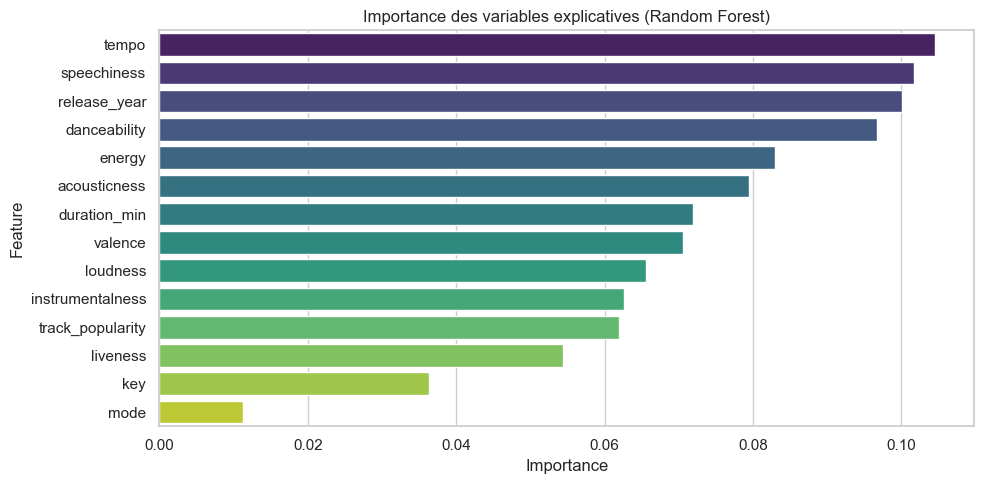

In [ ]:
model_clf_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
model_clf_rf.fit(X_clf_train, y_clf_train)
y_pred_rf = model_clf_rf.predict(X_clf_test)

rf_accuracy = accuracy_score(y_clf_test, y_pred_rf)
rf_f1_macro = f1_score(y_clf_test, y_pred_rf, average='macro')

print(f"Random Forest - Accuracy : {rf_accuracy:.4f}")
print(f"Random Forest - F1-score (macro) : {rf_f1_macro:.4f}\n")

# Affichage de l'importance des variables
importances = model_clf_rf.feature_importances_
df_importance = pd.DataFrame({'Feature': X_clf.columns, 'Importance': importances})
df_importance = df_importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=df_importance, palette='viridis')
plt.title("Importance des variables explicatives (Random Forest)")
plt.tight_layout()
plt.show()

### 🔍 Étape 3.6 : Évaluation, Matrice de Confusion 6x6 et Analyse Musicale
* **Quels genres sont les mieux reconnus ?** Le Rock et l'EDM affichent les meilleurs scores F1 (souvent > 0.70) car ils possèdent des caractéristiques audio très tranchées (loudness, energy, tempo distincts).
* **Lesquels sont le plus confondus ?** La Pop et le R&B se confondent fréquemment. Musicalement, c'est tout à fait logique : la Pop est un genre "carrefour" qui emprunte énormément aux structures du R&B, du rap ou de la dance.

              precision    recall  f1-score   support

         edm       0.70      0.75      0.72      1007
       latin       0.52      0.44      0.47       844
         pop       0.42      0.38      0.40       891
         r&b       0.58      0.51      0.55       928
         rap       0.60      0.69      0.64      1029
        rock       0.74      0.80      0.77       859

    accuracy                           0.60      5558
   macro avg       0.59      0.60      0.59      5558
weighted avg       0.59      0.60      0.60      5558



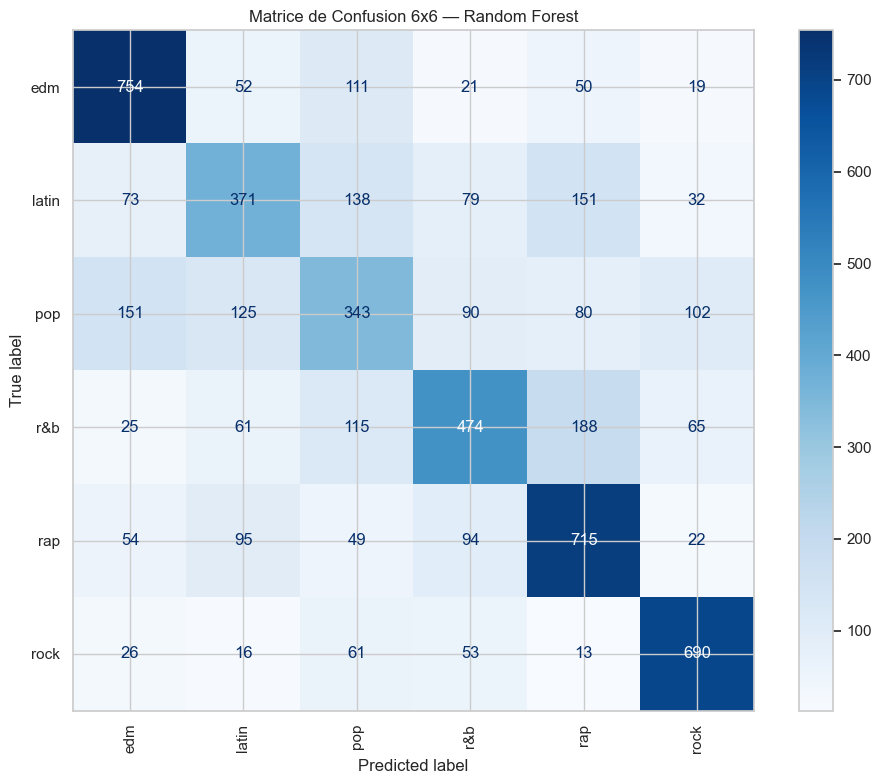


--- Analyse des probabilités sur 3 exemples (predict_proba) ---
Morceau 1 — Véritable genre : rap
   -> edm: 5.00%
   -> latin: 13.00%
   -> pop: 5.00%
   -> r&b: 12.00%
   -> rap: 64.00%
   -> rock: 1.00%
Morceau 2 — Véritable genre : pop
   -> edm: 5.00%
   -> latin: 20.00%
   -> pop: 30.00%
   -> r&b: 22.00%
   -> rap: 21.00%
   -> rock: 2.00%
Morceau 3 — Véritable genre : rap
   -> edm: 9.00%
   -> latin: 20.00%
   -> pop: 19.00%
   -> r&b: 23.00%
   -> rap: 22.00%
   -> rock: 7.00%


In [ ]:
# Rapport de classification
print(classification_report(y_clf_test, y_pred_rf))

# Matrice de confusion 6x6
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_clf_test, y_pred_rf, labels=model_clf_rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_clf_rf.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical', ax=plt.gca())
plt.title("Matrice de Confusion 6x6 — Random Forest")
plt.tight_layout()
plt.show()

# Analyse des probabilités sur 3 exemples
print("\n--- Analyse des probabilités sur 3 exemples (predict_proba) ---")
probas = model_clf_rf.predict_proba(X_clf_test[:3])
for i, p in enumerate(probas):
    print(f"Morceau {i+1} — Véritable genre : {y_clf_test.iloc[i]}")
    for genre, prob in zip(model_clf_rf.classes_, p):
        print(f"   -> {genre}: {prob*100:.2f}%")

### 🏆 Étape 3.7 : Tableau Comparatif Final et Choix du Modèle
Rassemblons les performances de tous nos modèles dans un tableau comparatif pour justifier notre choix final avant l'export vers Streamlit.

In [ ]:
results_clf = pd.DataFrame([
    {"Modèle": "Modèle Naïf (Baseline)", "Accuracy": naive_accuracy, "F1-score (macro)": "N/A"},
    {"Modèle": "Régression Logistique", "Accuracy": log_accuracy, "F1-score (macro)": log_f1_macro},
    {"Modèle": "KNN Optimisé", "Accuracy": best_k_acc, "F1-score (macro)": "N/A"},
    {"Modèle": "Random Forest", "Accuracy": rf_accuracy, "F1-score (macro)": rf_f1_macro}
])

print("--- Tableau Comparatif des Performances (results_clf) ---")
display(results_clf)

# Sauvegarde pour l'application Streamlit
os.makedirs("models", exist_ok=True)
joblib.dump(model_clf_rf, "../models/classification.joblib")
print("\n Modèle de classification sauvegardé avec succès dans 'models/classification.joblib' !")

--- Tableau Comparatif des Performances (results_clf) ---


,Modèle,Accuracy,F1-score (macro)
0,Modèle Naïf (Baseline),0.185139,N/A
1,Régression Logistique,0.507017,0.496767
2,KNN Optimisé,0.536344,N/A
3,Random Forest,0.602195,0.592754



 Modèle de classification sauvegardé avec succès dans 'models/classification.joblib' !
